In [1]:
import pandas as pd
import numpy as np
from sklearn import tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.metrics import (accuracy_score, precision_score, f1_score, ConfusionMatrixDisplay, recall_score)

from sklearn.ensemble import RandomForestClassifier

In [2]:
df = pd.read_csv("dataset.csv")
vs = pd.read_csv("validation.csv")
df.head()

,timestamp,temp_c,rolling_mean_5m,rolling_std_5m,rate_of_change_1m,excursion_phase
0,2026-11-18T21:27:59,4.56,4.548,0.045,0.00,normal
1,2026-11-18T21:28:29,4.56,4.542,0.038,0.00,normal
2,2026-11-18T21:28:59,4.56,4.536,0.029,0.00,normal
3,2026-11-18T21:29:29,4.50,4.530,0.030,-0.04,normal
4,2026-11-18T21:29:59,4.50,4.527,0.030,-0.04,normal


In [3]:
df["excursion_phase"].unique()
vs["excursion_phase"].unique()

<StringArray>
['excursion', 'warning', 'normal']
Length: 3, dtype: str

In [4]:
df["excursion_phase"] = np.where(df["excursion_phase"] == "excursion", 2, np.where(df["excursion_phase"] == "warning", 1, 0))
vs["excursion_phase"] = np.where(vs["excursion_phase"] == "excursion", 2, np.where(vs["excursion_phase"] == "warning", 1, 0))

In [5]:
df["excursion_phase"].unique()
vs["excursion_phase"].unique()

array([2, 1, 0])

In [6]:
# Dependent Variable
y = df["excursion_phase"]

# Independent Variable
x = df[[
    "temp_c",
    "rolling_mean_5m",
    "rolling_std_5m",
    "rate_of_change_1m"
]]

# Create training and test datasets.
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [7]:
RF = RandomForestClassifier(
    criterion = 'gini',
    n_estimators = 100,
    max_depth = 5,
    min_samples_split = 3,
    class_weight = 'balanced',
    random_state = 0
)

In [8]:
RF.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [9]:
labels = [
    "temp_c",
    "rolling_mean_5m",
    "rolling_std_5m",
    "rate_of_change_1m"
]

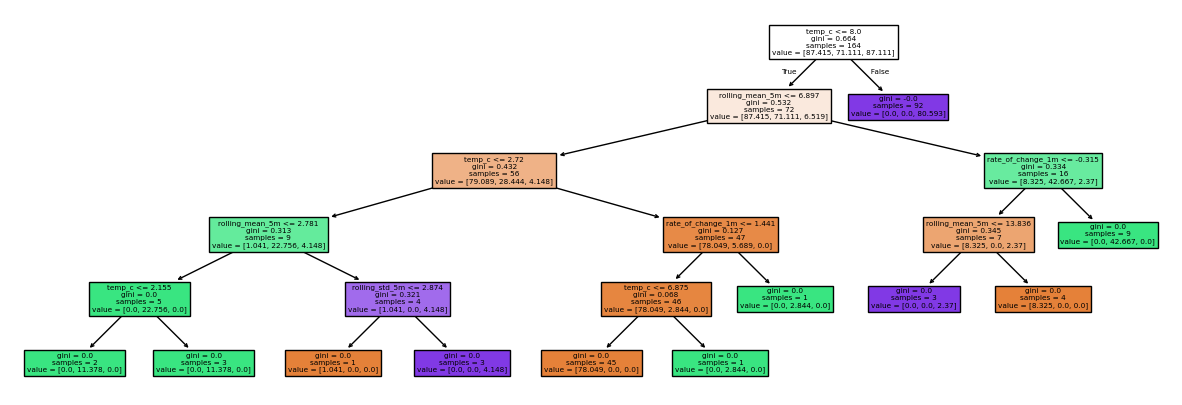

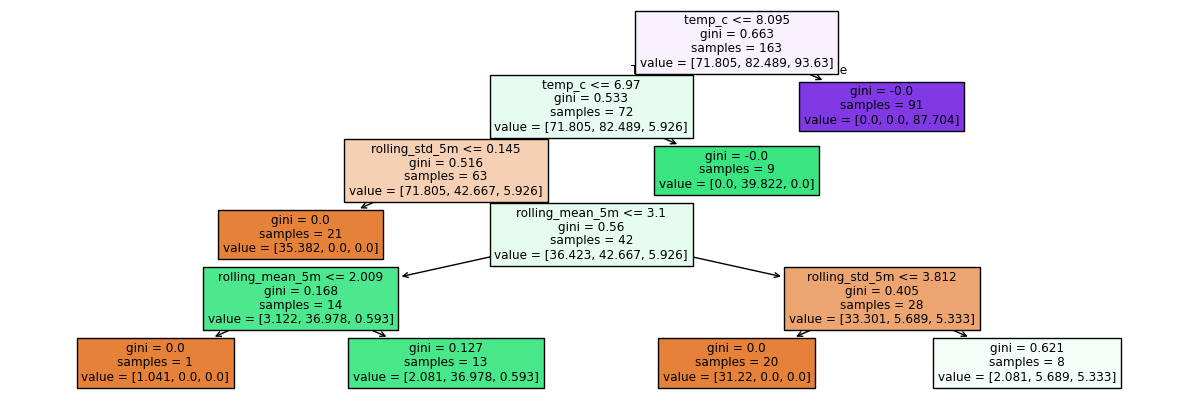

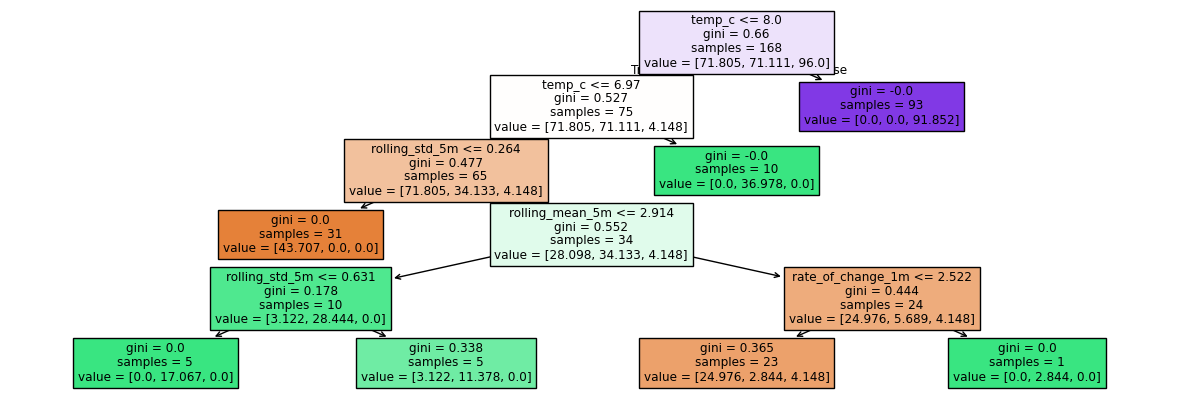

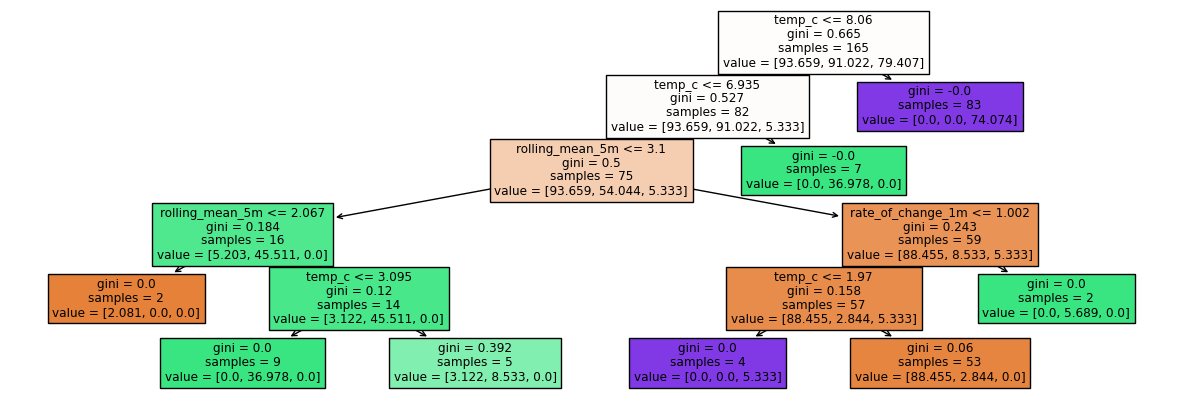

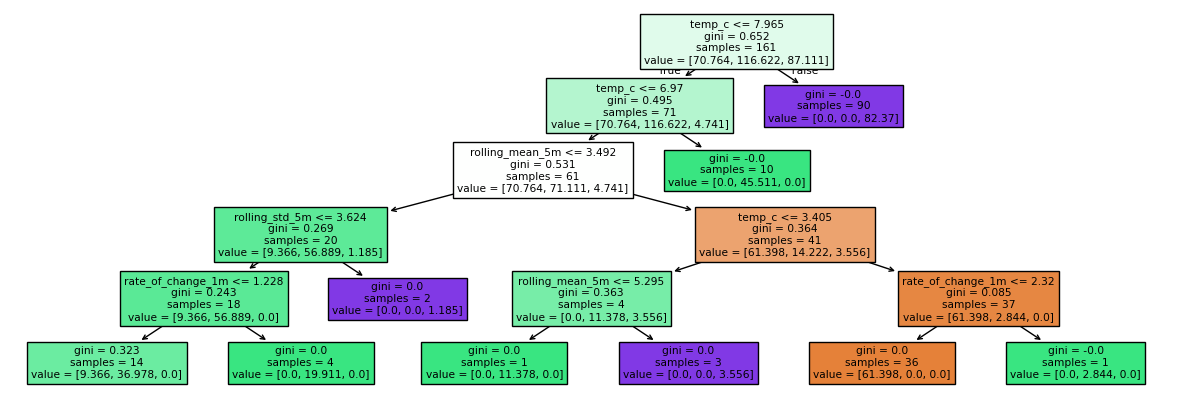

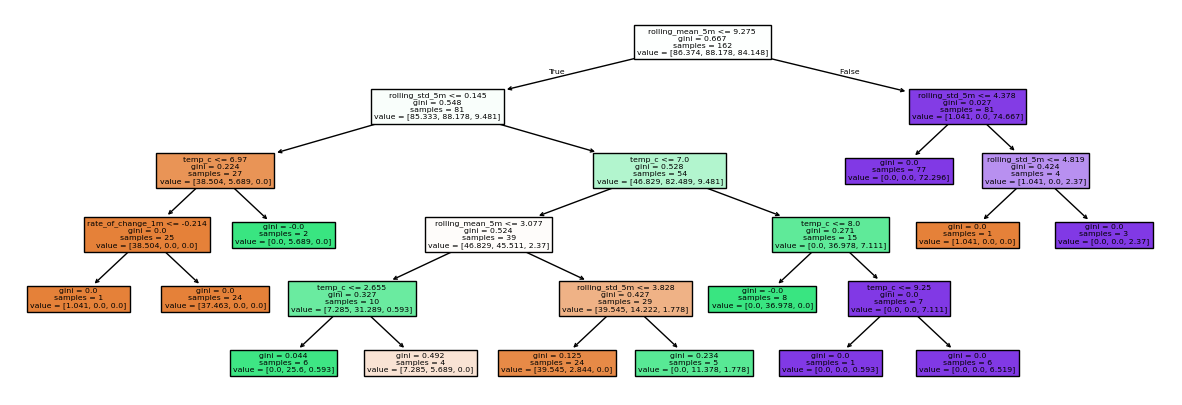

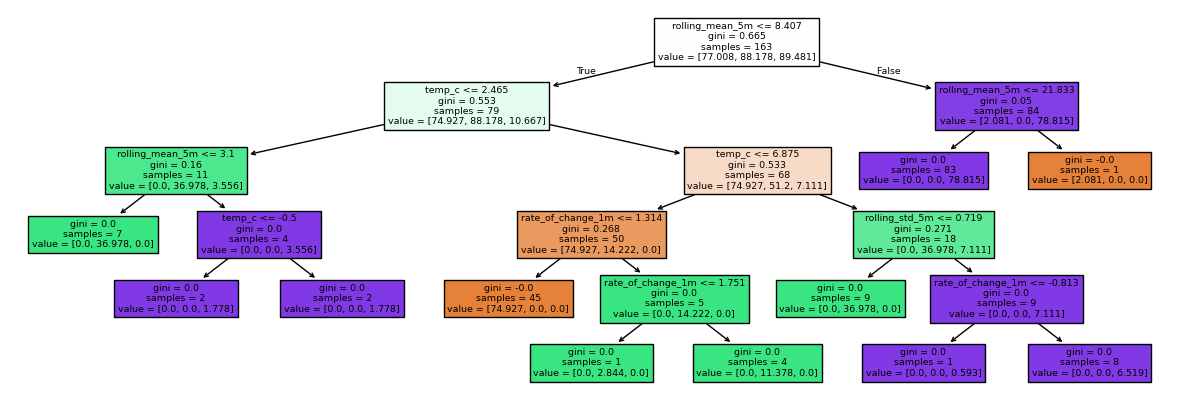

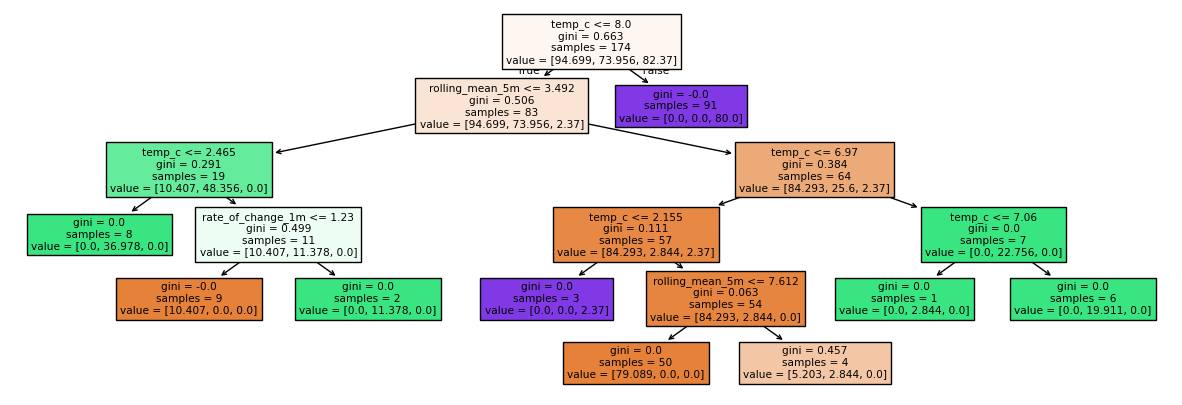

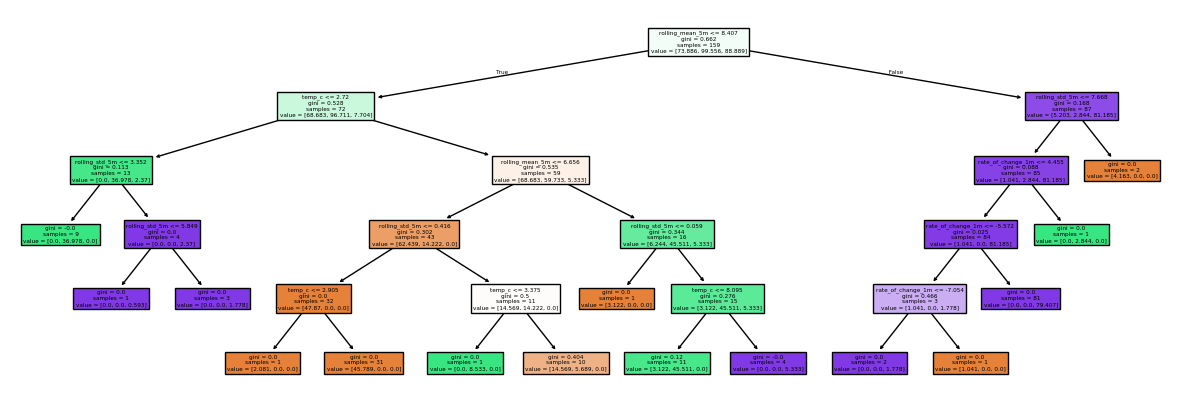

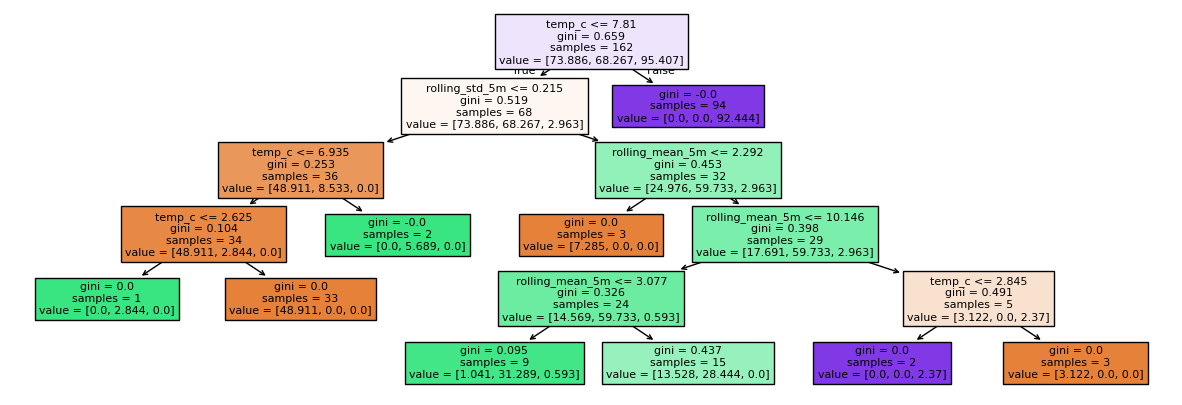

In [10]:
for i in range(10):
    fig = plt.figure(figsize=(15,5))
    
    # Tree 1 (Tree 1 = [0])
    tree.plot_tree(
        RF.estimators_[i],
        feature_names=labels,
        filled=True,
        impurity=True
    )
    plt.show()

In [11]:
df.head()

,timestamp,temp_c,rolling_mean_5m,rolling_std_5m,rate_of_change_1m,excursion_phase
0,2026-11-18T21:27:59,4.56,4.548,0.045,0.00,0
1,2026-11-18T21:28:29,4.56,4.542,0.038,0.00,0
2,2026-11-18T21:28:59,4.56,4.536,0.029,0.00,0
3,2026-11-18T21:29:29,4.50,4.530,0.030,-0.04,0
4,2026-11-18T21:29:59,4.50,4.527,0.030,-0.04,0


In [12]:
# 2026-11-19T11:10:40,fridge_01,9.88,9.928,0.058,0.0,excursion,
features = ["temp_c",
            "rolling_mean_5m", "rolling_std_5m", "rate_of_change_1m"]

predictions = pd.DataFrame([{
    "temp_c": 4.5,
    "rolling_mean_5m": 4.928,
    "rolling_std_5m": 0.658,
    "rate_of_change_1m": 2.8,
}])[features]

print(RF.predict(predictions))

[1]


In [13]:
val = pd.DataFrame(vs)

val["Predicted"] = RF.predict(val[features])

val.head()

,timestamp,temp_c,rolling_mean_5m,rolling_std_5m,rate_of_change_1m,excursion_phase,Predicted
0,2026-11-19T19:57:45,8.63,8.630,0.000,0.000,2,2
1,2026-11-19T19:58:15,8.19,8.410,0.220,0.000,2,2
2,2026-11-19T19:58:45,7.69,8.170,0.384,-0.939,1,1
3,2026-11-19T19:59:15,7.31,7.955,0.499,-0.879,1,1
4,2026-11-19T19:59:45,7.00,7.764,0.588,-0.794,1,1


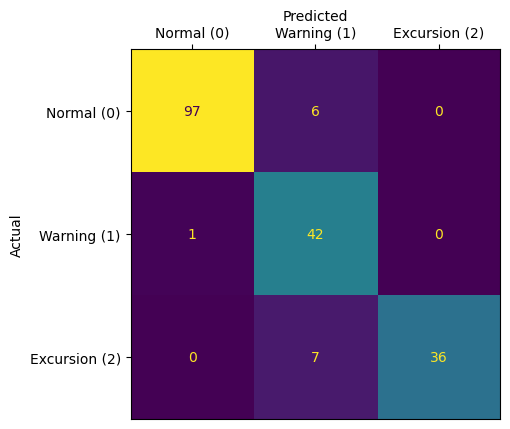

In [14]:
ConfMatrix = ConfusionMatrixDisplay.from_predictions(
    val["excursion_phase"],
    val["Predicted"],  
    labels = [0, 1, 2],
    colorbar=False,
    display_labels=[
        "Normal (0)",
        "Warning (1)",
        "Excursion (2)"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
ax = ConfMatrix.ax_
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.show()

In [15]:
print(list(X_train.columns))

['temp_c', 'rolling_mean_5m', 'rolling_std_5m', 'rate_of_change_1m']


In [16]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(RF, x, y, cv=5, scoring="f1_macro")
print(scores, scores.mean())

[0.90388933 0.80583453 0.7045177  1.         0.69104212] 0.8210567377313653


In [17]:
print(pd.Series(RF.feature_importances_, index=X_train.columns).sort_values(ascending=False))

temp_c               0.510959
rolling_mean_5m      0.320198
rolling_std_5m       0.098288
rate_of_change_1m    0.070555
dtype: float64


In [18]:
metrics.accuracy_score(val["excursion_phase"], val["Predicted"])

0.9259259259259259

In [19]:
1 - metrics.accuracy_score(val["excursion_phase"], val["Predicted"])

0.07407407407407407

In [20]:
print(recall_score(val["excursion_phase"], val["Predicted"], average=None))
print(recall_score(val["excursion_phase"], val["Predicted"], average="macro"))
print(recall_score(val["excursion_phase"], val["Predicted"], average="weighted"))

[0.94174757 0.97674419 0.8372093 ]
0.9185670203958757
0.9259259259259259


In [21]:
print("Precision Average:", precision_score(val["excursion_phase"], val["Predicted"], average=None))
print(precision_score(val["excursion_phase"], val["Predicted"], average="macro"))
print(precision_score(val["excursion_phase"], val["Predicted"], average="weighted"))

Precision Average: [0.98979592 0.76363636 1.        ]
0.9178107606679036
0.9406631916835998


In [23]:
print(f1_score(val["excursion_phase"], val["Predicted"], average=None))
print(f1_score(val["excursion_phase"], val["Predicted"], average="macro"))
print(f1_score(val["excursion_phase"], val["Predicted"], average="weighted"))

[0.96517413 0.85714286 0.91139241]
0.9112364638531273
0.9283595322658597


In [ ]:
import joblib
joblib.dump(RF, "RandomForest.joblib")